# Eye disease classifier inference

This notebook loads the existing trained ResNet50 checkpoint through `src.predictor.EyeDiseasePredictor` and runs inference on one image. It does not train or fine-tune a model. The configured class order is `0 = cataract`, `1 = glaucoma`, and `2 = normal`.

The final section demonstrates an optional local MedGemma chat through Ollama using synthetic classifier output only.

## 1. Environment and dependencies

Run this notebook with the project's existing Python environment. It checks the libraries used for inference and display; it does not install packages or change the environment.

In [1]:
import sys

import PIL
import matplotlib
import torch
import torchvision

print(f"Python:      {sys.version.split()[0]}")
print(f"PyTorch:     {torch.__version__}")
print(f"Torchvision: {torchvision.__version__}")
print(f"Pillow:      {PIL.__version__}")
print(f"Matplotlib:  {matplotlib.__version__}")
print(f"Inference device: {'cuda' if torch.cuda.is_available() else 'cpu'}")

Python:      3.12.10
PyTorch:     2.5.1+cu121
Torchvision: 0.20.1+cu121
Pillow:      12.2.0
Matplotlib:  3.10.8
Inference device: cuda


## 2. Project path configuration

The project root is found by searching the current directory and its parents. This supports starting Jupyter from either the project directory or `notebooks/`.

In [2]:
from pathlib import Path
import sys

candidates = (Path.cwd().resolve(), *Path.cwd().resolve().parents)
PROJECT_ROOT = next(
    (
        candidate
        for candidate in candidates
        if (candidate / "src" / "predictor.py").is_file()
        and (candidate / "best_eye_disease_model.pth").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the project root. Start Jupyter in the project directory "
        "or its notebooks directory."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")

Project root: D:\College\4th year\Projects\CAD


## 3. Locate the existing checkpoint

The checkpoint is used as-is. The model architecture and checkpoint-loading logic remain in `src/`; no training or fine-tuning is performed.

In [3]:
CHECKPOINT_PATH = PROJECT_ROOT / "best_eye_disease_model.pth"
if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f"Trained checkpoint not found: {CHECKPOINT_PATH}")

print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"Size: {CHECKPOINT_PATH.stat().st_size / (1024 * 1024):.1f} MiB")

Checkpoint: D:\College\4th year\Projects\CAD\best_eye_disease_model.pth
Size: 92.0 MiB


## 4. Initialize the existing predictor

`EyeDiseasePredictor` selects CUDA when available and otherwise uses CPU. It loads the checkpoint and applies the same preprocessing used by the existing inference implementation.

In [4]:
from src.predictor import CLASS_NAMES, EyeDiseasePredictor

predictor = EyeDiseasePredictor(checkpoint_path=CHECKPOINT_PATH)
print(f"Checkpoint loaded on {predictor.device}.")
print(f"Class order: {dict(enumerate(CLASS_NAMES))}")

Checkpoint loaded on cuda.
Class order: {0: 'cataract', 1: 'glaucoma', 2: 'normal'}


## 5. Select and display an image

For an actual test image, set `IMAGE_PATH` below to an absolute path or a path relative to the project root, for example `Path("test_images/my_image.jpg")`. Keep test images local and do not add patient-identifiable information to the repository. By default, the cell creates a synthetic non-medical placeholder so the inference flow can be smoke-tested without a dataset image.

Using a synthetic smoke-test placeholder; it is not an eye image.
Selected image: C:\Users\ASUS\AppData\Local\Temp\eye-inference-6npss34p\synthetic_smoke_test.png


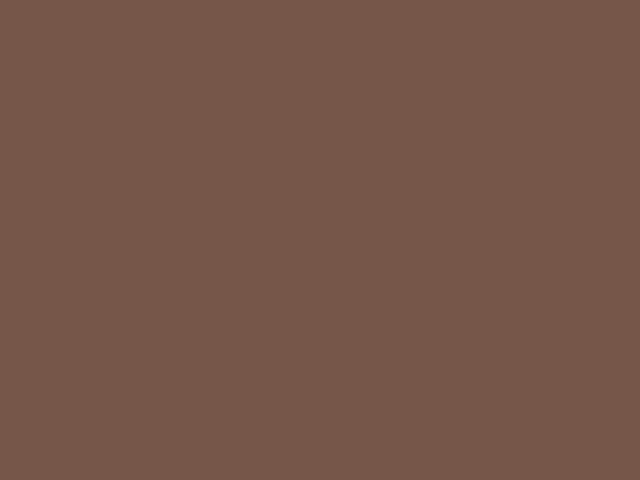

In [6]:
import tempfile

from PIL import Image
from IPython.display import display

# Replace None with Path("test_images/my_image.jpg") or an absolute image path.
IMAGE_PATH = None

if IMAGE_PATH is None:
    _sample_image_dir = tempfile.TemporaryDirectory(prefix="eye-inference-")
    IMAGE_PATH = Path(_sample_image_dir.name) / "synthetic_smoke_test.png"
    Image.new("RGB", (640, 480), color=(118, 86, 73)).save(IMAGE_PATH)
    print("Using a synthetic smoke-test placeholder; it is not an eye image.")
else:
    IMAGE_PATH = Path(IMAGE_PATH).expanduser()
    if not IMAGE_PATH.is_absolute():
        IMAGE_PATH = PROJECT_ROOT / IMAGE_PATH
    IMAGE_PATH = IMAGE_PATH.resolve()
    if not IMAGE_PATH.is_file():
        raise FileNotFoundError(f"Test image not found: {IMAGE_PATH}")

print(f"Selected image: {IMAGE_PATH}")
with Image.open(IMAGE_PATH) as image:
    display(image.convert("RGB"))

## 6. Run inference and inspect all class scores

The predictor returns the highest-scoring class and one softmax score for each configured class.

In [7]:
prediction = predictor.predict(IMAGE_PATH)

print(f"Predicted class: {prediction['predicted_class']}")
print("Softmax scores:")
for class_name in CLASS_NAMES:
    print(f"  {class_name:>9}: {prediction['scores'][class_name]:.6f}")

Predicted class: cataract
Softmax scores:
   cataract: 0.998822
   glaucoma: 0.000768
     normal: 0.000410


## 7. Interpreting the result and limitations

The three values are the model's softmax outputs for cataract, glaucoma, and normal; they sum to approximately 1 and the largest value determines the displayed class. They are not calibrated probabilities, a diagnosis, or evidence that the prediction is correct. Performance may vary with image quality, acquisition conditions, and differences from the training data. This research classifier has not been established here as a clinically validated tool and must not be used to make medical decisions.

## 8. Local MedGemma experiment with Ollama

This proof of concept sends a **synthetic classifier result only** to the local Ollama service; it does not send the selected image or a real classifier prediction. The classifier output is not calibrated, and adding an LLM does not make the classifier more accurate: the LLM can only explain the supplied scores, may generate unsupported wording, and inherits the classifier's uncertainty and limitations. Neither output is clinical advice or a diagnosis.

In [8]:
import json
import socket
import time
import urllib.error
import urllib.request

OLLAMA_BASE_URL = "http://localhost:11434"
OLLAMA_MODEL = "medgemma1.5:4b"
OLLAMA_READY = False
OLLAMA_MODEL_DIGEST = None

try:
    tags_request = urllib.request.Request(
        f"{OLLAMA_BASE_URL}/api/tags",
        headers={"Accept": "application/json"},
    )
    with urllib.request.urlopen(tags_request, timeout=5) as tags_response:
        tags_data = json.loads(tags_response.read().decode("utf-8"))
except urllib.error.HTTPError as error:
    print(f"Ollama returned HTTP status {error.code} while checking local models.")
except (TimeoutError, socket.timeout):
    print("The Ollama model check timed out. Confirm Ollama is running and rerun this cell.")
except urllib.error.URLError as error:
    if isinstance(error.reason, (TimeoutError, socket.timeout)):
        print("The Ollama model check timed out. Confirm Ollama is running and rerun this cell.")
    else:
        print(
            "Ollama is not reachable at http://localhost:11434. Start Ollama and "
            "rerun this cell to enable the optional local experiment."
        )
except OSError:
    print(
        "Ollama is not reachable at http://localhost:11434. Start Ollama and "
        "rerun this cell to enable the optional local experiment."
    )
except (json.JSONDecodeError, UnicodeError):
    print("Ollama returned an unreadable model list. The optional experiment was skipped.")
else:
    if not isinstance(tags_data, dict) or not isinstance(tags_data.get("models"), list):
        print("Ollama returned an unexpected model list. The optional experiment was skipped.")
    else:
        local_model = next(
            (
                model
                for model in tags_data["models"]
                if isinstance(model, dict) and model.get("name") == OLLAMA_MODEL
            ),
            None,
        )
        if local_model is None:
            print(
                f"The local model {OLLAMA_MODEL!r} is not available. "
                f"Run `ollama pull {OLLAMA_MODEL}` and rerun this cell."
            )
        else:
            OLLAMA_READY = True
            OLLAMA_MODEL_DIGEST = local_model.get("digest")
            print(f"Ollama is ready with {OLLAMA_MODEL}.")

Ollama is ready with medgemma1.5:4b.


In [9]:
SYNTHETIC_CLASSIFIER_OUTPUT = {
    "predicted_class": "glaucoma",
    "scores": {"cataract": 0.23, "glaucoma": 0.62, "normal": 0.15},
    "class_order": ["cataract", "glaucoma", "normal"],
    "score_note": "Uncalibrated softmax outputs, not calibrated probabilities.",
}

if OLLAMA_READY:
    system_instruction = (
        "You are explaining a synthetic research classifier output. You did not "
        "inspect the original eye image. Do not invent clinical findings or claim "
        "to independently diagnose the image. Explain only the supplied classifier "
        "output. Explicitly acknowledge uncertainty and limitations of the classifier. "
        "Do not prescribe treatment, and do not present your response as clinical advice. "
        "The supplied scores are uncalibrated softmax outputs, not calibrated probabilities."
    )
    user_message = (
        "Explain this synthetic classifier output for a research experiment. "
        "The scores are uncalibrated softmax outputs, not calibrated probabilities. "
        "Do not infer anything about an image.\n\n"
        + json.dumps(SYNTHETIC_CLASSIFIER_OUTPUT, indent=2)
    )
    chat_payload = json.dumps(
        {
            "model": OLLAMA_MODEL,
            "stream": False,
            "options": {
                "temperature": 0.2,
                "seed": 42,
                "num_predict": 300,
            },
            "messages": [
                {"role": "system", "content": system_instruction},
                {"role": "user", "content": user_message},
            ],
        }
    ).encode("utf-8")
    chat_request = urllib.request.Request(
        f"{OLLAMA_BASE_URL}/api/chat",
        data=chat_payload,
        headers={"Content-Type": "application/json", "Accept": "application/json"},
        method="POST",
    )

    request_started = time.perf_counter()
    try:
        with urllib.request.urlopen(chat_request, timeout=120) as chat_response:
            chat_response_body = chat_response.read()
        response_duration_seconds = time.perf_counter() - request_started
    except urllib.error.HTTPError as error:
        print(f"The local MedGemma request returned HTTP status {error.code}.")
    except (TimeoutError, socket.timeout):
        print("The local MedGemma request timed out. Check Ollama and rerun this cell.")
    except urllib.error.URLError as error:
        if isinstance(error.reason, (TimeoutError, socket.timeout)):
            print("The local MedGemma request timed out. Check Ollama and rerun this cell.")
        else:
            print("Could not connect to the local Ollama service. Check that it is running and rerun this cell.")
    except OSError:
        print("Could not read a response from the local Ollama service. Check that it is running and rerun this cell.")
    else:
        try:
            chat_data = json.loads(chat_response_body.decode("utf-8"))
            if not isinstance(chat_data, dict):
                raise ValueError
            response_message = chat_data.get("message")
            if not isinstance(response_message, dict):
                raise ValueError
            generated_response = response_message.get("content")
            if not isinstance(generated_response, str) or not generated_response.strip():
                raise ValueError
        except (json.JSONDecodeError, UnicodeError, ValueError):
            print("Ollama returned an unexpected response. Check the local model and rerun this cell.")
        else:
            experiment_metadata = {
                "model": chat_data.get("model") or OLLAMA_MODEL,
                "model_digest": OLLAMA_MODEL_DIGEST,
                "response_duration_seconds": round(response_duration_seconds, 2),
                "generation_options": {
                    "temperature": 0.2,
                    "seed": 42,
                    "maximum_generated_tokens": 300,
                },
                "input": "synthetic classifier output only",
            }
            for count_field in ("prompt_eval_count", "eval_count"):
                count_value = chat_data.get(count_field)
                if isinstance(count_value, int) and not isinstance(count_value, bool):
                    experiment_metadata[count_field] = count_value
            for duration_field in (
                "total_duration",
                "load_duration",
                "prompt_eval_duration",
                "eval_duration",
            ):
                duration_value = chat_data.get(duration_field)
                if isinstance(duration_value, (int, float)) and not isinstance(duration_value, bool):
                    experiment_metadata[f"{duration_field}_nanoseconds"] = duration_value
                    experiment_metadata[f"{duration_field}_seconds"] = round(duration_value / 1_000_000_000, 3)
            print("Experiment metadata:", json.dumps(experiment_metadata, indent=2))
            print("\nGenerated research-oriented explanation (not clinical advice):\n")
            print(generated_response)
            print(
                "\nA successful response only demonstrates a local API exchange; "
                "it does not establish medical accuracy."
            )
else:
    print("The local MedGemma request was skipped because Ollama/model availability was not confirmed.")

Experiment metadata: {
  "model": "medgemma1.5:4b",
  "model_digest": "433252621ab154668b5d8be6aff6c1b771bacba045e46e6193da8d6ad1630f2c",
  "response_duration_seconds": 15.89,
  "generation_options": {
    "temperature": 0.2,
    "seed": 42,
    "maximum_generated_tokens": 300
  },
  "input": "synthetic classifier output only",
  "prompt_eval_count": 227,
  "eval_count": 300,
  "total_duration_nanoseconds": 13852719000,
  "total_duration_seconds": 13.853,
  "load_duration_nanoseconds": 6554108100,
  "load_duration_seconds": 6.554,
  "prompt_eval_duration_nanoseconds": 187894000,
  "prompt_eval_duration_seconds": 0.188,
  "eval_duration_nanoseconds": 7072458000,
  "eval_duration_seconds": 7.072
}

Generated research-oriented explanation (not clinical advice):

<unused94> thought
The user wants me to explain a synthetic classifier output for a research experiment.
The output provides:
- `predicted_class`: "glaucoma"
- `scores`: { "cataract": 0.23, "glaucoma": 0.62, "normal": 0.15 }
- `cl